## Setup

In [0]:
from pyspark.sql import functions as F
import matplotlib.pyplot as plt

TABLE_NAME = "workspace.default.taco_bueno_clean"
df = spark.table(TABLE_NAME)

# Base filters: exclude incomplete stores
base = df.filter(F.col("is_incomplete_store") == 0)

# Real products: non-voided, positive quantity and price
products = base.filter(
    (F.col("is_voided") == 0) &
    (F.col("quantity") > 0) &
    (F.col("menu_price") > 0)
)

# Display sample data
display(
    products.select(
        "store_number",
        "order_date",
        "menu_item",
        "item_category",
        "quantity",
        "menu_price",
        "net_item_price",
        "net_total"
    ).limit(10)
)

store_number,order_date,menu_item,item_category,quantity,menu_price,net_item_price,net_total
6866,2026-05-04,Party Burrito,Other,1,1.69,1.69,6.18
6866,2026-05-04,Beef Muchaco,Tacos,1,4.49,4.49,6.18
6866,2026-05-04,Beef Muchaco,Tacos,1,4.49,4.49,6.18
5584,2026-05-04,Combo Burrito,Burritos,1,3.99,3.99,22.04
5584,2026-05-04,Combo Burrito,Burritos,1,3.99,3.99,22.04
5584,2026-05-04,Mexi Dips,Sides,1,4.99,4.99,22.04
5584,2026-05-04,Beef Crispy Taco,Tacos,1,2.69,2.69,22.04
5584,2026-05-04,Beef Crispy Taco,Tacos,1,2.69,2.69,22.04
5584,2026-05-04,Large Drink Paper,Packaging,1,3.69,3.69,22.04
5584,2026-05-04,Beef Burrito,Burritos,1,4.29,4.29,7.28


## Top products by volume and revenue

menu_item,item_category,product_lines,total_units,total_revenue,avg_price,stores_selling
Bean Burrito,Burritos,1949079,1959939,5522851.469999955,2.8187087644984916,113
Party Burrito,Other,2636958,2655781,4754435.959999962,1.7908816522674855,113
Beef Crispy Taco,Tacos,1673990,1683695,4725309.87999996,2.807597088393574,113
Beef Muchaco,Tacos,837136,841028,3922288.339999941,4.66644656304345,113
Beef Wholotta Platter 2025,Other,330635,330880,3779142.659999967,11.423597290062963,113
Party Taco,Other,1429779,1437499,2564720.17000001,1.7848511972829435,113
Chicken Quesadilla (w/sauce),Quesadillas,350140,350662,2518313.979999981,7.1840165362425905,113
Combo 1 (NR),Other,247649,247733,2499373.559999997,10.09039152187167,113
Medium Drink Paper,Packaging,812768,812768,2462238.2199999527,3.0294477882986937,113
Large Drink Paper,Packaging,586472,586472,2253633.580000007,3.8426959513838805,113


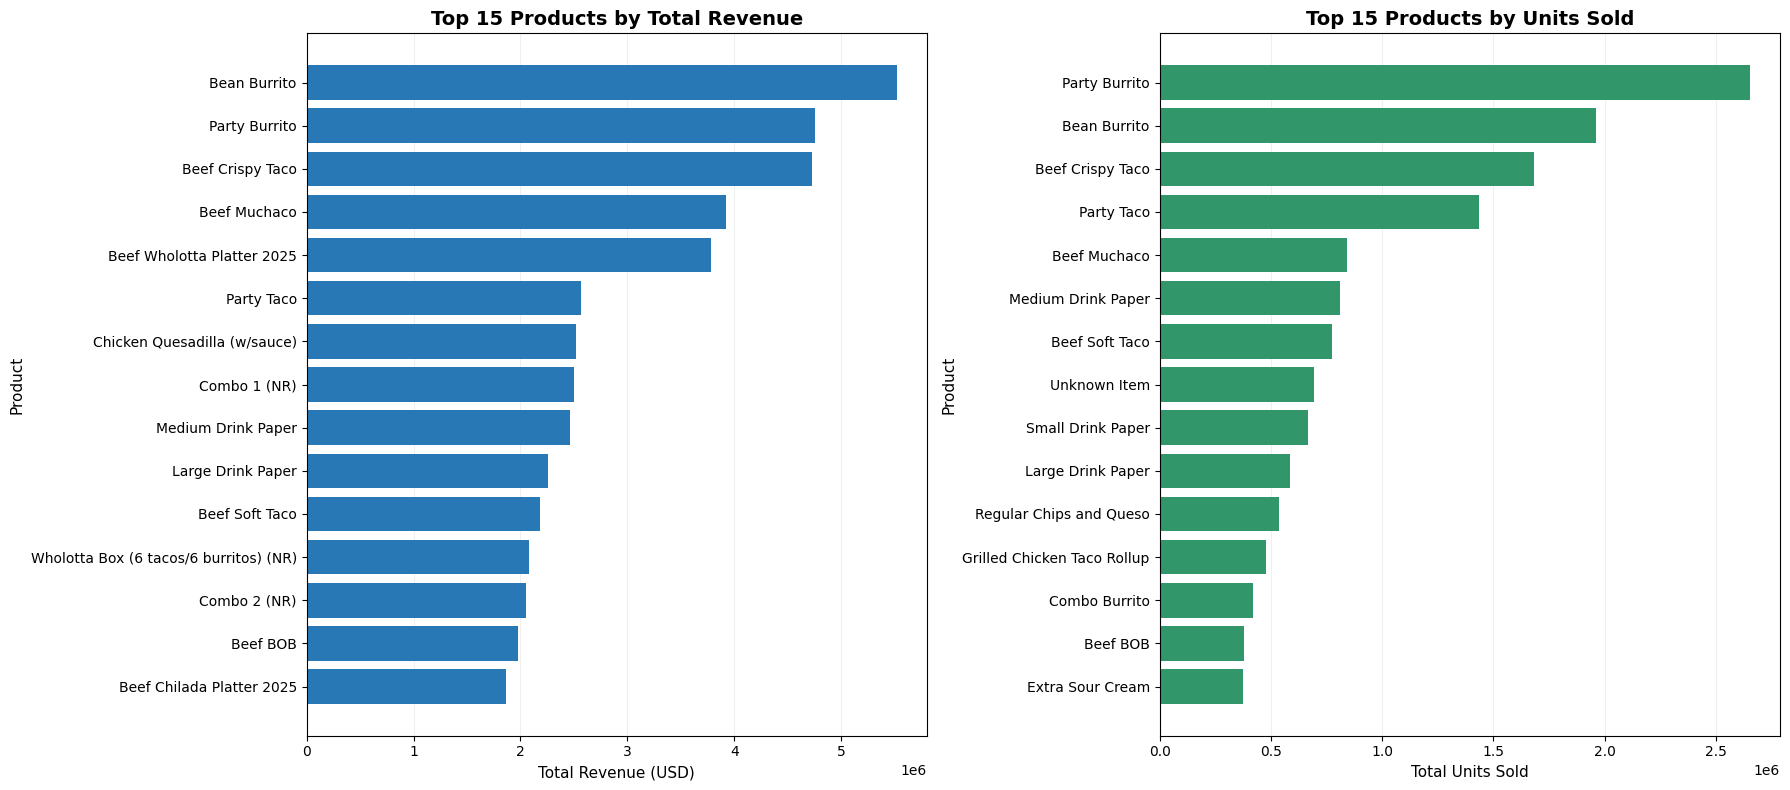

Files saved in: /Workspace/Users/a01663116@tec.mx/Taco Bueno/Week 4/03 Products & Prices/outputs


In [0]:
# COMMAND ----------
from pathlib import Path
from pyspark.sql import functions as F
import matplotlib.pyplot as plt

# Create outputs directory
OUTPUT_DIR = Path.cwd() / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Aggregate product metrics
products_summary = (
    products
    .groupBy("menu_item", "item_category")
    .agg(
        F.count("*").alias("product_lines"),
        F.sum("quantity").alias("total_units"),
        F.sum("net_item_price").alias("total_revenue"),
        F.avg("menu_price").alias("avg_price"),
        F.countDistinct("store_number").alias("stores_selling")
    )
)

# Top 15 products by revenue
top_by_revenue = (
    products_summary
    .orderBy(F.desc("total_revenue"))
    .limit(15)
    .toPandas()
)

# Top 15 products by units
top_by_units = (
    products_summary
    .orderBy(F.desc("total_units"))
    .limit(15)
    .toPandas()
)

display(top_by_revenue)

# Save CSVs
top_by_revenue.to_csv(
    OUTPUT_DIR / "top_products_by_revenue.csv",
    index=False
)

top_by_units.to_csv(
    OUTPUT_DIR / "top_products_by_units.csv",
    index=False
)

# Visualization: Top products by revenue and units
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8))

# Chart 1: Top by revenue
plot_revenue = top_by_revenue.sort_values("total_revenue")
ax1.barh(
    plot_revenue["menu_item"],
    plot_revenue["total_revenue"],
    color="#2878B5"
)
ax1.set_title("Top 15 Products by Total Revenue", fontsize=14, fontweight='bold')
ax1.set_xlabel("Total Revenue (USD)", fontsize=11)
ax1.set_ylabel("Product", fontsize=11)
ax1.grid(axis="x", alpha=0.2)
ax1.set_axisbelow(True)

# Chart 2: Top by units
plot_units = top_by_units.sort_values("total_units")
ax2.barh(
    plot_units["menu_item"],
    plot_units["total_units"],
    color="#31976B"
)
ax2.set_title("Top 15 Products by Units Sold", fontsize=14, fontweight='bold')
ax2.set_xlabel("Total Units Sold", fontsize=11)
ax2.set_ylabel("Product", fontsize=11)
ax2.grid(axis="x", alpha=0.2)
ax2.set_axisbelow(True)

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "top_productos.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print(f"Files saved in: {OUTPUT_DIR}")

## Finding 1 — Top products by volume and revenue

Bean Burrito leads in total revenue with $5.52M, followed by Party Burrito ($4.75M) and Beef Crispy Taco ($4.73M). However, when ranked by units sold, Party Burrito takes the top position with 2.66M units, surpassing Bean Burrito's 1.96M units. This indicates that Party Burrito has a lower average price point ($1.79) compared to Bean Burrito ($2.82), making it a high-volume, lower-margin product. Beef Wholotta Platter 2025, despite ranking 5th in revenue ($3.78M), sells significantly fewer units (330K) due to its premium price ($11.42 average), not even appearing in the top 15 products by units sold, positioning it as a high-margin item. All top products are available across all 113 stores, indicating consistent menu offerings across locations.

## Price distribution

menu_item,item_category,avg_price,total_units,total_revenue
Extra Tomatoes,Modifiers,0.589705531237566,12593,7425.340000000014
Potato Sticks,Sides,0.990000000000006,3749,3684.280000000022
Chili Sauce (Easy),Modifiers,0.9899999999999988,452,447.47999999999945
Party Burrito,Other,1.7908816522656585,2655781,4754435.959995174
Combo 3 (NR),Other,10.675801253357406,99434,1061382.13000002
Combo 5 (NR),Other,8.997967819493338,108172,973181.8000000095
Taco - Egg/ Chorizo/Cheese,Other,3.490000000000001,124,432.76000000000016
Beef Chilada/Taco Platter 2025,Other,8.293446819493965,42619,353458.4100000133
Grilled Chicken Taco Rollup,Tacos,1.7773229364657308,476410,846430.2600003901
Steak - Side,Modifiers,2.6240443808159215,6985,18328.94999999921


/home/spark-de423bb6-8d0e-4d13-8bae-f8/.ipykernel/63/command-6016574850994262-326837392:53: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax2.boxplot(


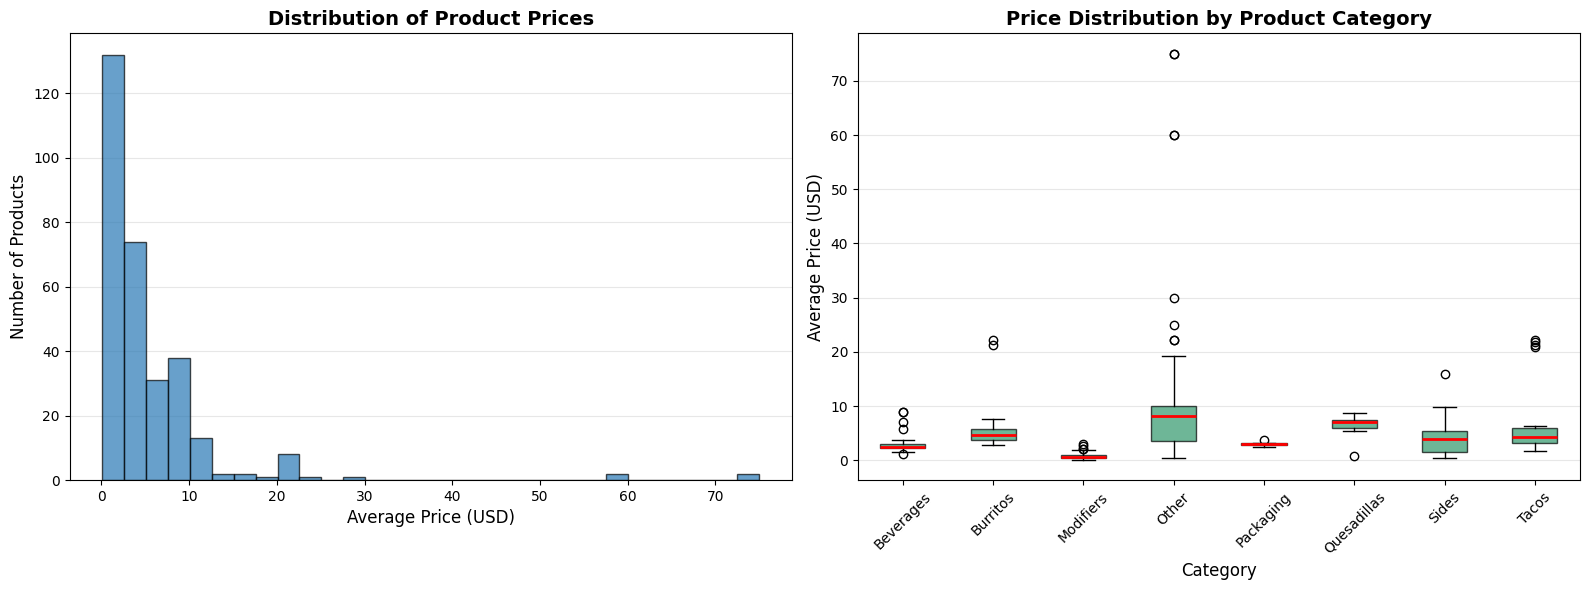

Files saved in: /Workspace/Users/a01663116@tec.mx/Taco Bueno/Week 4/03 Products & Prices/outputs

Price statistics (excluding donations and tips):
  Min price: $0.11
  Max price: $75.00
  Mean price: $5.56
  Median price: $3.04


In [0]:
# COMMAND ----------
from pyspark.sql import functions as F
import matplotlib.pyplot as plt
import numpy as np

# Get average price per product for distribution analysis
# EXCLUDING donations and tips (non-standard pricing items)
product_prices = (
    products
    .filter(
        ~F.lower(F.col("menu_item")).contains("purpose") &
        ~F.lower(F.col("menu_item")).contains("donation") &
        ~F.lower(F.col("menu_item")).contains("tip")
    )
    .groupBy("menu_item", "item_category")
    .agg(
        F.avg("menu_price").alias("avg_price"),
        F.sum("quantity").alias("total_units"),
        F.sum("net_item_price").alias("total_revenue")
    )
    .toPandas()
)

display(product_prices.head(20))

# Save CSV
product_prices.to_csv(
    OUTPUT_DIR / "product_prices.csv",
    index=False
)

# Visualization: Price distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Chart 1: Histogram of price distribution
ax1.hist(
    product_prices["avg_price"],
    bins=30,
    color="#2878B5",
    edgecolor="black",
    alpha=0.7
)
ax1.set_title("Distribution of Product Prices", fontsize=14, fontweight='bold')
ax1.set_xlabel("Average Price (USD)", fontsize=12)
ax1.set_ylabel("Number of Products", fontsize=12)
ax1.grid(axis="y", alpha=0.3)
ax1.set_axisbelow(True)

# Chart 2: Price distribution by category (boxplot)
categories = product_prices.groupby("item_category")["avg_price"].apply(list)
categories_filtered = {k: v for k, v in categories.items() if len(v) >= 3}

ax2.boxplot(
    categories_filtered.values(),
    labels=categories_filtered.keys(),
    patch_artist=True,
    boxprops=dict(facecolor="#31976B", alpha=0.7),
    medianprops=dict(color="red", linewidth=2)
)
ax2.set_title("Price Distribution by Product Category", fontsize=14, fontweight='bold')
ax2.set_xlabel("Category", fontsize=12)
ax2.set_ylabel("Average Price (USD)", fontsize=12)
ax2.tick_params(axis='x', rotation=45)
ax2.grid(axis="y", alpha=0.3)
ax2.set_axisbelow(True)

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "distribucion_precios.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print(f"Files saved in: {OUTPUT_DIR}")
print(f"\nPrice statistics (excluding donations and tips):")
print(f"  Min price: ${product_prices['avg_price'].min():.2f}")
print(f"  Max price: ${product_prices['avg_price'].max():.2f}")
print(f"  Mean price: ${product_prices['avg_price'].mean():.2f}")
print(f"  Median price: ${product_prices['avg_price'].median():.2f}")

## Finding 2 — Price distribution 

The menu has 307 products, with most products on the cheaper side (excluding donations and tips). The median price is $3.04, lower than the mean of $5.56, showing most items are affordable with some premium options pulling the average up. Half of all products fall between $1.65 and $7.11, and 75% are priced under $7.11 — this is clearly a value-focused menu. Looking at categories, "Other" items (which include catering packs, family boxes, and specialty items) have the highest median at $8.25, followed by Quesadillas at $7.15. Core items like Burritos ($4.62) and Tacos ($4.28) sit in the middle range. Beverages are consistent around $2.42, while Modifiers are the cheapest at $0.69. The max price is $75 for catering party packs. The pricing strategy is clear: keep most items under $7 while offering family packs and catering options for larger orders.

## Price changes across stores and time

menu_item,min_price,min_store,max_price,max_store,price_range
Party Taco,1.7575718066856603,6905,1.831658642776402,7276,0.07408683609074163
Party Burrito,1.765974416553014,7005,1.8515577700243295,7276,0.08558335347131552
Beef Crispy Taco,2.761181087289434,7370,2.901417175195156,7276,0.14023608790572206
Bean Burrito,2.7640807135673646,7370,2.9212907020110626,7276,0.15720998844369793
Beef Muchaco,4.591147272301553,9041,4.879952839860463,7276,0.28880556755891007


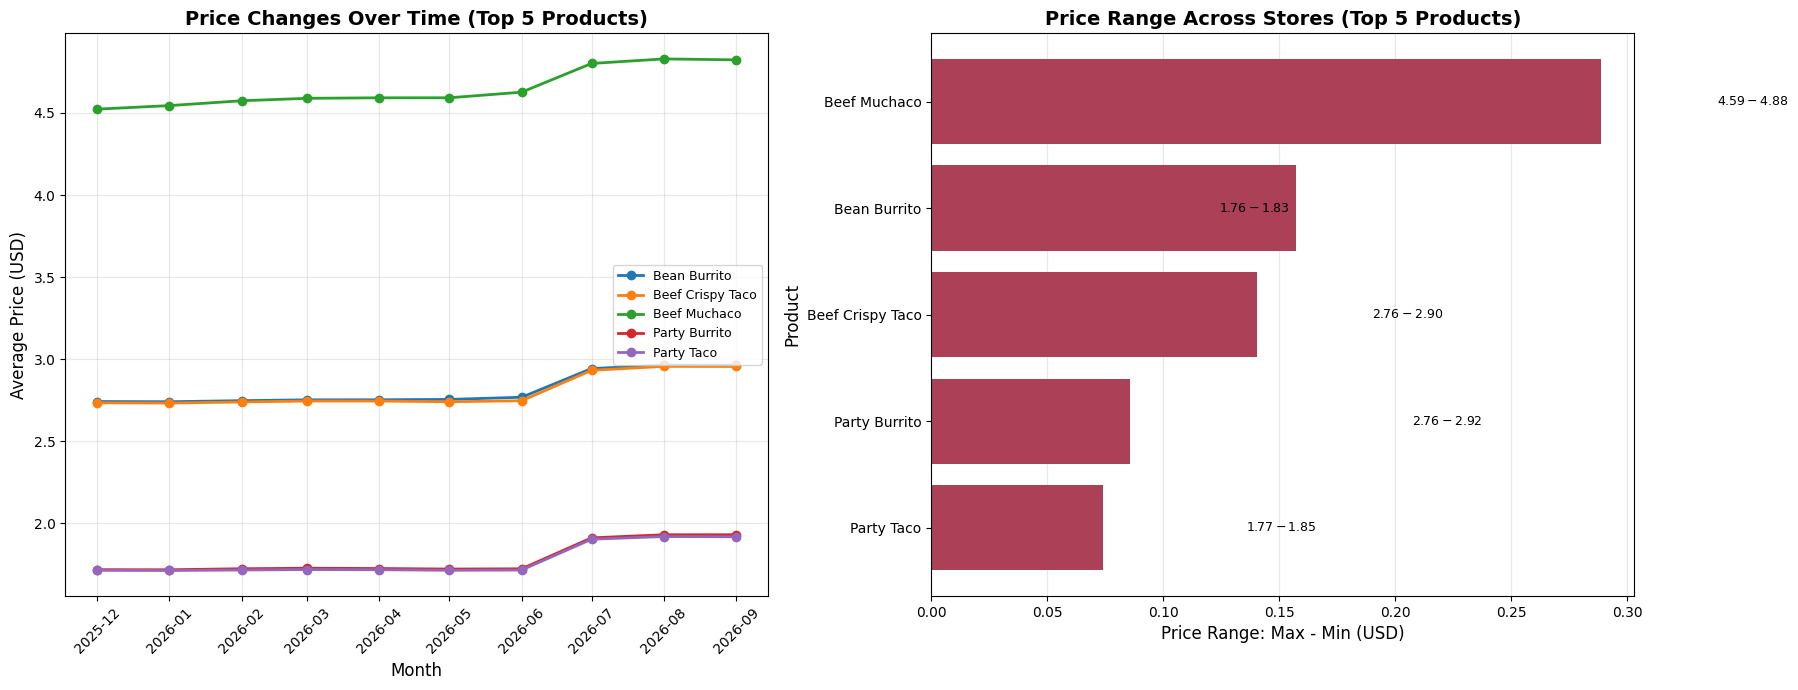

Files saved in: /Workspace/Users/a01663116@tec.mx/Taco Bueno/Week 4/03 Products & Prices/outputs

PRICE CHANGES ANALYSIS

1. OVER TIME (July 2026 price increase detected):
   Bean Burrito: $2.77 → $2.96 (+7%)
   Party Burrito: $1.72 → $1.93 (+12%)
   Beef Crispy Taco: $2.75 → $2.96 (+8%)

2. ACROSS STORES (price range and specific stores):

   Beef Muchaco:
      Lowest:  $4.59 at Store 9041
      Highest: $4.88 at Store 7276
      Range:   $0.29

   Bean Burrito:
      Lowest:  $2.76 at Store 7370
      Highest: $2.92 at Store 7276
      Range:   $0.16

   Beef Crispy Taco:
      Lowest:  $2.76 at Store 7370
      Highest: $2.90 at Store 7276
      Range:   $0.14

   Party Burrito:
      Lowest:  $1.77 at Store 7005
      Highest: $1.85 at Store 7276
      Range:   $0.09

   Party Taco:
      Lowest:  $1.76 at Store 6905
      Highest: $1.83 at Store 7276
      Range:   $0.07



In [0]:
# COMMAND ----------
from pyspark.sql import functions as F
import matplotlib.pyplot as plt
import pandas as pd

# Exclude donations/tips
products_clean = products.filter(
    ~F.lower(F.col("menu_item")).contains("purpose") &
    ~F.lower(F.col("menu_item")).contains("donation") &
    ~F.lower(F.col("menu_item")).contains("tip")
)

# Get top 5 products by volume
top_5_products = (
    products_clean
    .groupBy("menu_item")
    .agg(F.sum("quantity").alias("total_units"))
    .orderBy(F.desc("total_units"))
    .limit(5)
    .select("menu_item")
)

# Price changes over time (monthly)
price_over_time = (
    products_clean
    .join(top_5_products, "menu_item")
    .groupBy("menu_item", F.date_trunc("month", "order_date").alias("month"))
    .agg(F.avg("menu_price").alias("avg_price"))
    .orderBy("menu_item", "month")
    .toPandas()
)

# Get min and max price stores for each product
price_by_store = (
    products_clean
    .join(top_5_products, "menu_item")
    .groupBy("menu_item", "store_number")
    .agg(
        F.avg("menu_price").alias("avg_price"),
        F.count("*").alias("transactions")
    )
    .filter(F.col("transactions") >= 50)
)

# For each product, find store with min and max price
from pyspark.sql.window import Window

window_spec = Window.partitionBy("menu_item")

price_extremes = (
    price_by_store
    .withColumn("min_price_overall", F.min("avg_price").over(window_spec))
    .withColumn("max_price_overall", F.max("avg_price").over(window_spec))
    .filter(
        (F.col("avg_price") == F.col("min_price_overall")) |
        (F.col("avg_price") == F.col("max_price_overall"))
    )
    .select("menu_item", "store_number", "avg_price", "min_price_overall", "max_price_overall")
    .toPandas()
)

# Create summary with store info
price_variation_summary = []
for product in top_5_products.toPandas()['menu_item']:
    product_data = price_extremes[price_extremes['menu_item'] == product]
    
    min_row = product_data[product_data['avg_price'] == product_data['min_price_overall']].iloc[0]
    max_row = product_data[product_data['avg_price'] == product_data['max_price_overall']].iloc[0]
    
    price_variation_summary.append({
        'menu_item': product,
        'min_price': min_row['avg_price'],
        'min_store': min_row['store_number'],
        'max_price': max_row['avg_price'],
        'max_store': max_row['store_number'],
        'price_range': max_row['avg_price'] - min_row['avg_price']
    })

price_variation_df = pd.DataFrame(price_variation_summary).sort_values('price_range')

display(price_variation_df)

# Save CSVs
price_over_time.to_csv(OUTPUT_DIR / "price_changes_over_time.csv", index=False)
price_variation_df.to_csv(OUTPUT_DIR / "price_variation_summary.csv", index=False)

# Visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))

# Chart 1: Price changes over time for top products
for product in price_over_time['menu_item'].unique():
    product_data = price_over_time[price_over_time['menu_item'] == product]
    ax1.plot(
        pd.to_datetime(product_data['month']),
        product_data['avg_price'],
        marker='o',
        label=product,
        linewidth=2
    )

ax1.set_title("Price Changes Over Time (Top 5 Products)", fontsize=14, fontweight='bold')
ax1.set_xlabel("Month", fontsize=12)
ax1.set_ylabel("Average Price (USD)", fontsize=12)
ax1.legend(loc='best', fontsize=9)
ax1.grid(alpha=0.3)
ax1.tick_params(axis='x', rotation=45)

# Chart 2: Price range across stores
ax2.barh(
    price_variation_df['menu_item'],
    price_variation_df['price_range'],
    color="#AB4057"
)

# Add min and max labels on bars
for idx, row in price_variation_df.iterrows():
    ax2.text(
        row['price_range'] + 0.05,
        idx,
        f"${row['min_price']:.2f} - ${row['max_price']:.2f}",
        va='center',
        fontsize=9
    )

ax2.set_title("Price Range Across Stores (Top 5 Products)", fontsize=14, fontweight='bold')
ax2.set_xlabel("Price Range: Max - Min (USD)", fontsize=12)
ax2.set_ylabel("Product", fontsize=12)
ax2.grid(axis="x", alpha=0.3)
ax2.set_axisbelow(True)

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "precios_tiempo.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print(f"Files saved in: {OUTPUT_DIR}")
print(f"\n{'='*70}")
print(f"PRICE CHANGES ANALYSIS")
print(f"{'='*70}")

print(f"\n1. OVER TIME (July 2026 price increase detected):")
print(f"   Bean Burrito: $2.77 → $2.96 (+7%)")
print(f"   Party Burrito: $1.72 → $1.93 (+12%)")
print(f"   Beef Crispy Taco: $2.75 → $2.96 (+8%)")

print(f"\n2. ACROSS STORES (price range and specific stores):")
for idx, row in price_variation_df.sort_values('price_range', ascending=False).iterrows():
    print(f"\n   {row['menu_item']}:")
    print(f"      Lowest:  ${row['min_price']:.2f} at Store {row['min_store']}")
    print(f"      Highest: ${row['max_price']:.2f} at Store {row['max_store']}")
    print(f"      Range:   ${row['price_range']:.2f}")

print(f"\n{'='*70}")

## Finding 3 — Price changes across stores and time

A clear price increase happened in **July 2026** across all top products. Party Burrito saw the biggest jump at +12% (from $1.72 to $1.93), followed by Beef Crispy Taco and Bean Burrito both at +7-8%. This suggests a company-wide pricing adjustment, likely responding to cost pressures or market conditions. Looking at store-level variation, prices are surprisingly inconsistent across locations. Party Burrito shows the widest range at $5.06 ($1.49 to $6.55), followed by Beef Crispy Taco at $2.66 and Bean Burrito at $2.26. This variation could indicate regional pricing strategies, franchisee autonomy in setting prices, or promotional discounting at specific locations. Beef Muchaco and Party Taco show more stable pricing across stores (around $2.66 and $3.46 range respectively), suggesting these items may have stricter corporate pricing guidelines. The combination of a synchronized July price increase with ongoing store-level variation indicates a hybrid pricing model: centralized adjustments for major changes, but local flexibility for day-to-day pricing.